In [45]:
import time
import numpy as np
import matplotlib.pyplot as plt
import warnings
from scipy.linalg import expm
from scipy.optimize import least_squares


# Importa as bibliotecas desenvolvida para o projeto
import quantum_tomography as qt
import entropyreg as er

In [46]:
# Funções criadas pela IA que ainda preciso entender o pq foram feitas
def rho_a_partir_de_u(u, H, Q_list, epsilon):
    operador = sum(u_i * Q_i for u_i, Q_i in zip(u, Q_list)) - H
    return expm(operador / epsilon)


def normalizar_rho(rho):
    tr = np.trace(rho).real
    if not np.isfinite(tr) or tr <= 0:
        raise ValueError("A exponencial não produziu um traço positivo e finito.")
    return rho / tr


def entropia_von_neumann(rho):
    rho_h = (rho + rho.conj().T) / 2
    autovalores = np.linalg.eigvalsh(rho_h)
    autovalores = np.clip(autovalores, 0.0, None)
    positivos = autovalores[autovalores > 1e-14]
    return float(-np.sum(positivos * np.log(positivos)))


def estado_gibbs(H, beta):
    """Estado térmico exp(-beta H)/Z. Função auxiliar deste notebook."""
    return qt.QuantState(normalizar_rho(expm(-beta * H)))


def montar_observaveis_pauli(n_qubits):
    nomes = ["I" * n_qubits] + qt.pauli_basis_strings(n_qubits)
    matrizes = [qt.pauli_string_to_matrix(nome) for nome in nomes]
    return nomes, matrizes


def rodar_estocastico_com_historico(H, Q_list, q, epsilon, k, lr,
                                    max_iters=5000, tol=1e-6, seed=0,
                                    check_every=10):
    """
    Atualiza k coordenadas sorteadas. A cada check_every passos, calcula
    a norma do gradiente completo para avaliar/parar o método.
    """
    rng = np.random.default_rng(seed)
    u = np.zeros(len(q), dtype=float)
    m = len(q)
    historico = [[0, np.linalg.norm(er.dual_gradient(u, H, Q_list, q, epsilon))]]
    inicio = time.perf_counter()

    for t in range(1, max_iters + 1):
        grad_parcial, _ = er.stochastic_gradient(
            u, H, Q_list, q, epsilon, rng=rng, k=k
        )
        if not np.all(np.isfinite(grad_parcial)):
            break
        u -= lr * grad_parcial

        if t % check_every == 0:
            # k=m faz stochastic_gradient devolver todas as componentes:
            # portanto, aqui temos o gradiente completo.
            grad_completo, _ = er.stochastic_gradient(
                u, H, Q_list, q, epsilon, rng=rng, k=m
            )
            norma = np.linalg.norm(grad_completo)
            historico.append([t, norma])
            if np.isfinite(norma) and norma < tol:
                break

    tempo = time.perf_counter() - inicio
    return u, t, np.asarray(historico), tempo

Sanity check, verificação de que ambos os métodos funcionam para um mesmo problema com os mesmos parâmetros.

In [47]:
Q = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]
q = [1, 0.7, 0.4]
H = 0
epsilon = 1

# Teste com Gradient Ascent
pistar_data = er.reconstruct_pi(H, Q, q, epsilon, lr=1, max_iters=10000, tol=1e-6)
pistar = pistar_data[0]

print("Com o método de Gradient Ascent:")
print("Valores das médias com os observáveis I, Sigma_x, Sigma_y:" )
print(np.trace(pistar), np.trace(pistar @ Q[1]), np.trace(pistar @ Q[2]))
print("Número de iterações: ", pistar_data[2])
print("Matriz reconstruída pi*:")
print(pistar)

# Teste com Stochastic Gradient Ascent
stocpistar_data = er.reconstruct_spi(H, Q, q, epsilon, max_iters=5000, lr=1, tol=1e-6, k=2, count_it=1)
stocpistar, stoc_u_opt, stoc_n_it, stoc_pi_grad  = stocpistar_data
stoc_grad_data = np.array(stoc_pi_grad)

print("Com o método de Stochastic Gradient Ascent:")
print("Valores das médias com os observáveis I, Sigma_x, Sigma_y:" )
print(np.trace(stocpistar), np.trace(stocpistar @ Q[1]), np.trace(stocpistar @ Q[2]))
print("iterações:", stoc_n_it)
print("Matriz reconstruída pi*:")
print(stocpistar)


Com o método de Gradient Ascent:
Valores das médias com os observáveis I, Sigma_x, Sigma_y:
(1.0000008181897577-4.1777418156342424e-17j) (0.7000002472614089-2.7755575615628914e-17j) (0.4000001412922337+0j)
Número de iterações:  56
Matriz reconstruída pi*:
[[0.50000041+4.80325509e-18j 0.35000012-2.00000071e-01j]
 [0.35000012+2.00000071e-01j 0.50000041-4.65806732e-17j]]
Com o método de Stochastic Gradient Ascent:
Valores das médias com os observáveis I, Sigma_x, Sigma_y:
(1.0000000001282152-1.0194436133805656e-17j) (0.6999999783829212-5.551115123125783e-17j) (0.3999999874537122+5.551115123125783e-17j)
iterações: 100
Matriz reconstruída pi*:
[[0.5       +2.53539514e-17j 0.34999999-1.99999994e-01j]
 [0.34999999+1.99999994e-01j 0.5       -3.55483875e-17j]]


Definimos agora um estado alvo de 3 qubits para realizar a comparação entre os métodos, e então, escolhermos um para prosseguir nossa abordagem.

In [48]:
n_qubits = 3
estado_alvo = qt.random_mixture_of_pures(dim=2**n_qubits, rank=4, seed=17)

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
q = qt.measure_observables(estado_alvo, nomes_obs)
H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
epsilon = 1.0

print(estado_alvo)
print("Número de observáveis:", len(Q))
print("Traço do estado-alvo:", np.trace(estado_alvo.rho).real)
print("Autovalores do estado-alvo:", np.linalg.eigvalsh(estado_alvo.rho))

<QuantState (3 qubits, Misto (posto 4), pureza=0.336)>
Número de observáveis: 64
Traço do estado-alvo: 1.0
Autovalores do estado-alvo: [-4.88560586e-17 -2.24320419e-17  3.35882833e-18  3.35699553e-17
  9.90608868e-02  1.26475398e-01  3.13921218e-01  4.60542498e-01]


In [49]:
lr_comparacao = 0.5
tol = 1e-6
check_every = 10
max_iters = 100000

# Gradient Descent completo
t0 = time.perf_counter()
gd_data = er.gradient_descent(
    H, Q, q, epsilon, max_iters=max_iters, lr=lr_comparacao, tol=tol
)
tempo_gd = time.perf_counter() - t0
u_gd, it_gd, us_gd, grad_gd = gd_data

# Método estocástico com k coordenadas por iteração
t0 = time.perf_counter()
u_st, it_st, hist_st = er.sgd(
    H, Q, q, epsilon, k=len(Q)//2, lr=lr_comparacao,
    n_iter=max_iters, tol=tol, seed=0,
    check_every=check_every, count_it=check_every
)
tempo_st = time.perf_counter() - t0

rho_gd = normalizar_rho(rho_a_partir_de_u(u_gd, H, Q, epsilon))
rho_st = normalizar_rho(rho_a_partir_de_u(u_st, H, Q, epsilon))

print("Gradient Descent")
print("iterações:", it_gd, "| tempo (s):", round(tempo_gd, 4))
print("norma final do gradiente:", np.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon)))
print("fidelidade:", qt.fidelidade(rho_gd, estado_alvo.rho))

print("\nMétodo estocástico")
print("iterações:", it_st, "| tempo (s):", round(tempo_st, 4))
print("norma final do gradiente:", np.linalg.norm(er.dual_gradient(u_st, H, Q, q, epsilon)))
print("fidelidade:", qt.fidelidade(rho_st, estado_alvo.rho))

Gradient Descent
iterações: 100000 | tempo (s): 16.1765
norma final do gradiente: 1.4139716064896302e-05
fidelidade: 0.9999900226908442

Método estocástico
iterações: 100000 | tempo (s): 15.5021
norma final do gradiente: 3.024788892237474e-05
fidelidade: 0.9999799623257319


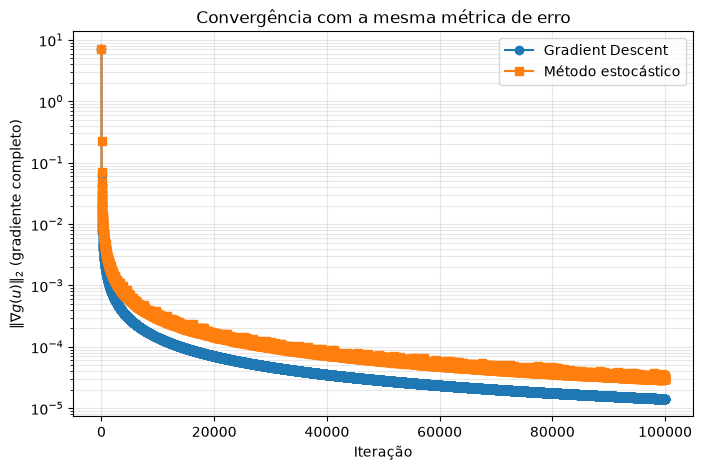

In [50]:
# O GD registra todos os passos; selecionamos os mesmos instantes usados no SGD.
hist_gd = np.asarray(grad_gd)
hist_gd = hist_gd[hist_gd[:, 0] % check_every == 0]
grad_gd_final = np.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon))
if hist_gd[-1, 0] != it_gd:
    hist_gd = np.vstack([hist_gd, [it_gd, grad_gd_final]])

hist_st = np.asarray(hist_st)
grad_inicial = np.linalg.norm(
    er.dual_gradient(np.zeros(len(q)), H, Q, q, epsilon)
)
hist_st = np.vstack([[0, grad_inicial], hist_st])

plt.figure(figsize=(8, 5))
plt.semilogy(hist_gd[:, 0], hist_gd[:, 1], "o-", label="Gradient Descent")
plt.semilogy(hist_st[:, 0], hist_st[:, 1], "s-", label="Método estocástico")
plt.xlabel("Iteração")
plt.ylabel(r"$\|\nabla g(u)\|_2$ (gradiente completo)")
plt.title("Convergência com a mesma métrica de erro")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

Selecionamos então o stochastic method pois ele aparenta funcionar melhor na questão de memória para problemas com dimensionalidade maior. Desse modo, agora vamos definir um estado arbitrário alvo, e verificar a convergência do método variando tanto o learning rate como o epsilon(correspondente à temperatura).

In [51]:
n_qubits = 3
estado_alvo = qt.random_mixture_of_pures(dim=2**n_qubits, seed=35)

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
q = qt.measure_observables(estado_alvo, nomes_obs)
H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)

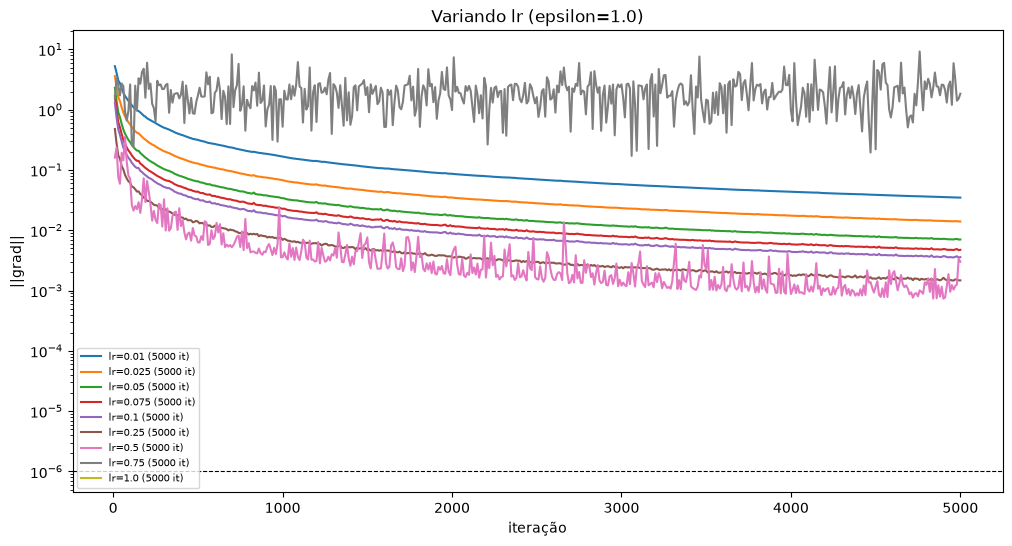

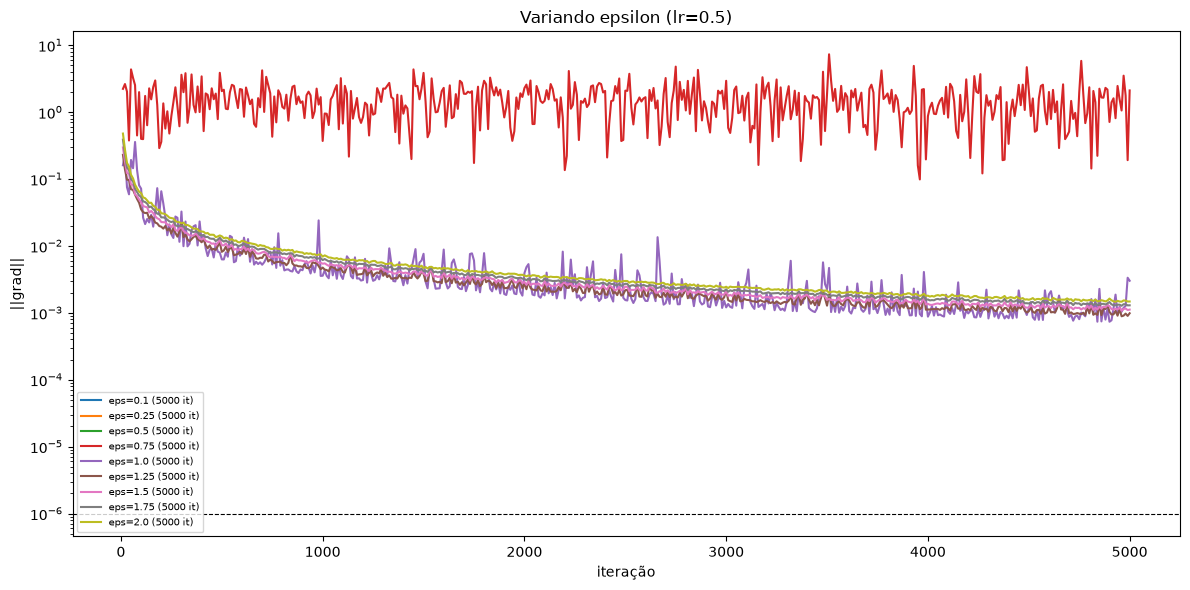

In [52]:
tol_fix = 1e-6
check_every_fix = 50
max_iters_fix = 5000

seeds = range(5)
epsilon_values = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_values = [0.01,0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75, 1.0]

lr_fix = 0.5
epsilon_fix = 1.0

k = len(Q) // 2


def rodar(lr, epsilon):
    u, n_it, hist = er.sgd(H, Q, q, epsilon, k=k, lr=lr, n_iter=max_iters_fix,
                        tol=tol_fix, seed=0, check_every=check_every_fix, count_it=10)
    hist = np.array(hist)
    return hist[:, 0], hist[:, 1], n_it


fig1, ax1 = plt.subplots(figsize=(12, 6))
fig2, ax2 = plt.subplots(figsize=(12, 6))

for lr in lr_values:
    t, g, n_it = rodar(lr, epsilon_fix)
    ax1.semilogy(t, g, label=f"lr={lr} ({n_it} it)")
ax1.set_title(f"Variando lr (epsilon={epsilon_fix})")

for eps in epsilon_values:
    t, g, n_it = rodar(lr_fix, eps)
    ax2.semilogy(t, g, label=f"eps={eps} ({n_it} it)")
ax2.set_title(f"Variando epsilon (lr={lr_fix})")

for a in [ax1, ax2]:
    a.axhline(tol_fix, color="k", ls="--", lw=0.8)
    a.set_xlabel("iteração")
    a.set_ylabel("||grad||")
    a.legend(fontsize=7)

plt.tight_layout()
plt.show()

Agora, o experimentos que faremos é definir uma lista de diferentes tipos de estados, escolher parâmetros que façam sentido para a resolução de cada um deles, e verificar a convergência do método com a regularização entrópica para cada um desses tipos de estado.

Um dos testes que parece fazer sentido, é aumentar a dimensionalidade do problema e ver até que ponto a máquina é capaz de resolver, vamos definir o tipo de estado (e parâmetros que pareçam razoáveis) que pelos testes feitos, parece ser o que melhor converge, para determinar um upper boundary para essa questão.

Outro teste que me pareceu interessante fazer foi pegar um estado alvo com dimensionalidade alta e verificar a partir de alguma medida de distância entre estados, como o método responde a medida que aumentamos o número de observáveis que sabemos as medidas, para assim determinar (claro, de forma limitada) um limiar a partir de quando o estado encontrado é perto o "suficiente" do estado alvo

Agora, vamos usar o qutip para alguma visualização legal, não sei ainda oq fazer